In [1]:
# If xgboost has not been previously installed you can use pip
# Run in terminal or notebook
!pip install xgboost

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GridSearchCV

# Load dataset
df = pd.read_csv("churn.csv")

# Check for missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   

In [3]:
# Define features and target variable
X = df.drop(columns=['churn'])  # Assuming 'Churn' is the target variable
y = df['churn']

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Identify categorical columns
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# Initialize OneHotEncoder
encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

# Fit and transform on training data
X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded = encoder.transform(X_test[categorical_cols])

# Convert encoded arrays to DataFrames
X_train_encoded_df = pd.DataFrame(X_train_encoded, index=X_train.index, columns=encoder.get_feature_names_out(categorical_cols))
X_test_encoded_df = pd.DataFrame(X_test_encoded, index=X_test.index, columns=encoder.get_feature_names_out(categorical_cols))

# Drop original categorical columns and concatenate encoded features
X_train = pd.concat([X_train.drop(columns=categorical_cols), X_train_encoded_df], axis=1)
X_test = pd.concat([X_test.drop(columns=categorical_cols), X_test_encoded_df], axis=1)

/home/data-architect/anaconda3/envs/ml-env/lib/python3.9/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Random Forest Model Performance:
              precision    recall  f1-score   support

       False       0.88      1.00      0.94       570
        True       0.92      0.24      0.38        97

    accuracy                           0.89       667
   macro avg       0.90      0.62      0.66       667
weighted avg       0.89      0.89      0.86       667



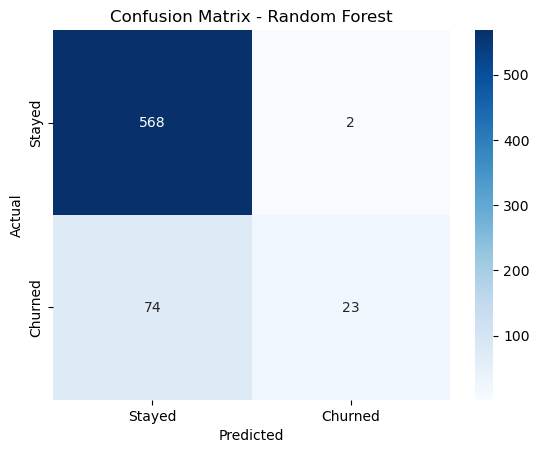

In [4]:
# Train a Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Model Performance:")
print(classification_report(y_test, y_pred_rf))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

AdaBoost Model Performance:
              precision    recall  f1-score   support

       False       0.87      0.99      0.92       570
        True       0.59      0.10      0.18        97

    accuracy                           0.86       667
   macro avg       0.73      0.55      0.55       667
weighted avg       0.83      0.86      0.81       667



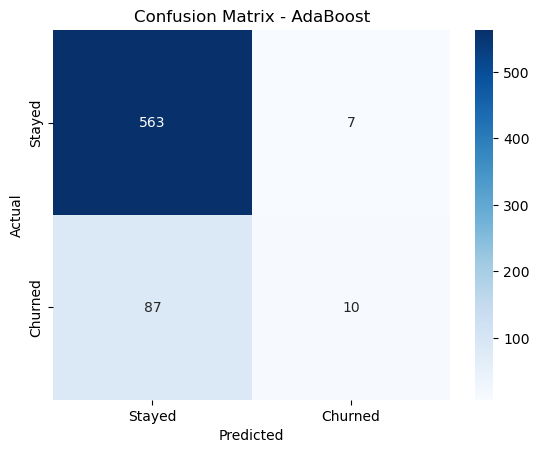

In [5]:
# Train AdaBoost model
adaboost_model = AdaBoostClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
adaboost_model.fit(X_train, y_train)

# Make predictions
y_pred_ada = adaboost_model.predict(X_test)

# Evaluate AdaBoost model
print("AdaBoost Model Performance:")
print(classification_report(y_test, y_pred_ada))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred_ada)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - AdaBoost')
plt.show()

Gradient Boosting Model Performance:
              precision    recall  f1-score   support

       False       0.94      0.99      0.96       570
        True       0.88      0.60      0.71        97

    accuracy                           0.93       667
   macro avg       0.91      0.79      0.84       667
weighted avg       0.93      0.93      0.92       667



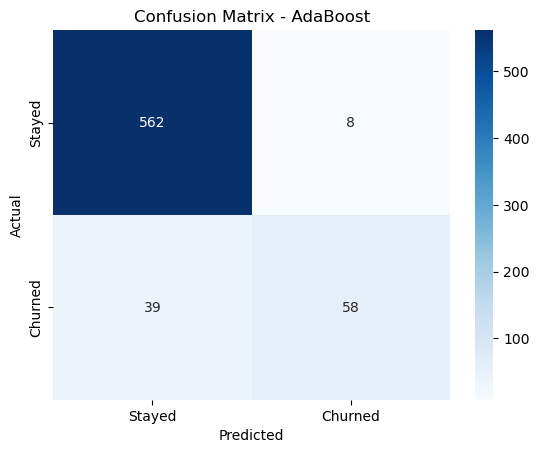

In [6]:
# Train Gradient Boosting model
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

# Make predictions
y_pred_gb = gb_model.predict(X_test)

# Evaluate Gradient Boosting model
print("Gradient Boosting Model Performance:")
print(classification_report(y_test, y_pred_gb))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred_gb)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - AdaBoost')
plt.show()

/home/data-architect/anaconda3/envs/ml-env/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [08:19:43] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBoost Model Performance:
              precision    recall  f1-score   support

       False       0.95      0.98      0.96       570
        True       0.88      0.67      0.76        97

    accuracy                           0.94       667
   macro avg       0.91      0.83      0.86       667
weighted avg       0.94      0.94      0.94       667



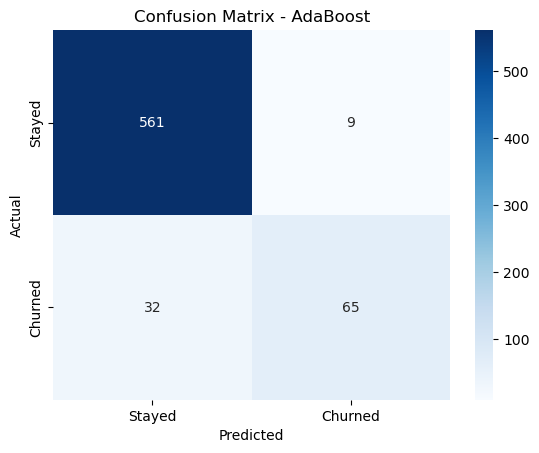

In [7]:
# Train XGBoost model
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, use_label_encoder=False, eval_metric="logloss")
xgb_model.fit(X_train, y_train)


# Make predictions
y_pred_xgb = xgb_model.predict(X_test)


# Evaluate XGBoost model
print("XGBoost Model Performance:")
print(classification_report(y_test, y_pred_xgb))


# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - AdaBoost')
plt.show()

In [8]:
# Define parameter grid, keep max depth low (weak learners)
# More estimators means longer time needed to train
param_grid = {'n_estimators': [100, 200, 300],
'learning_rate': [0.01, 0.05, 0.1],
'max_depth': [3, 5, 7]}

# Instanstiate GridSearch and select metric to score
grid_search = GridSearchCV(xgb_model, 
                           param_grid, 
cv=5, 
scoring='accuracy', 
n_jobs=-1)

# Fit model to train
grid_search.fit(X_train, y_train)

# Evaluate GS results
print("Best parameters from grid search:")
print(grid_search.best_params_)
print(f"Best cross-validation score: {grid_search.best_score_:.3f}")
print(f"Best training score: {grid_search.best_estimator_.score(X_train, y_train):.3f}")

/home/data-architect/anaconda3/envs/ml-env/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [08:19:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/data-architect/anaconda3/envs/ml-env/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [08:19:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/data-architect/anaconda3/envs/ml-env/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [08:19:53] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/data-architect/anaconda3/envs/ml-env/lib/python3.9/site-packages/xgboost/core.py:158: UserWarning: [08:19:54] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/home/data-architect/anacond

Best parameters from grid search:
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Best cross-validation score: 0.958
Best training score: 0.981


Final Model Accuracy: 0.95
Final Model Performance Report:
              precision    recall  f1-score   support

       False       0.95      0.98      0.97       570
        True       0.89      0.72      0.80        97

    accuracy                           0.95       667
   macro avg       0.92      0.85      0.88       667
weighted avg       0.94      0.95      0.94       667



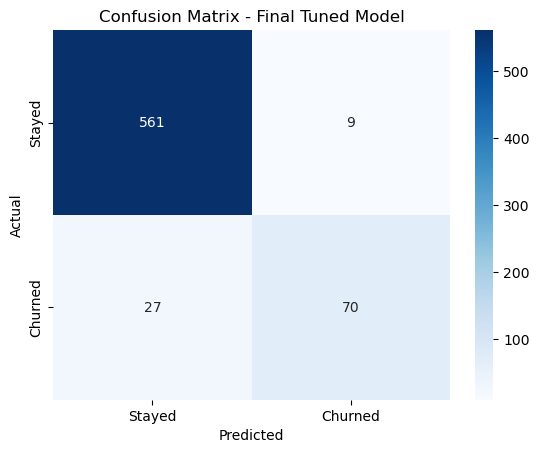

In [9]:
# Extract best/final model
best_xgb = grid_search.best_estimator_


# Make final predictions on the test set
y_pred_final = best_xgb.predict(X_test)


# Evaluate final model performance
accuracy = accuracy_score(y_test, y_pred_final)
print(f"Final Model Accuracy: {accuracy:.2f}")


# Display classification report
print("Final Model Performance Report:")
print(classification_report(y_test, y_pred_final))


# Generate final confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_final)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Final Tuned Model')
plt.show()

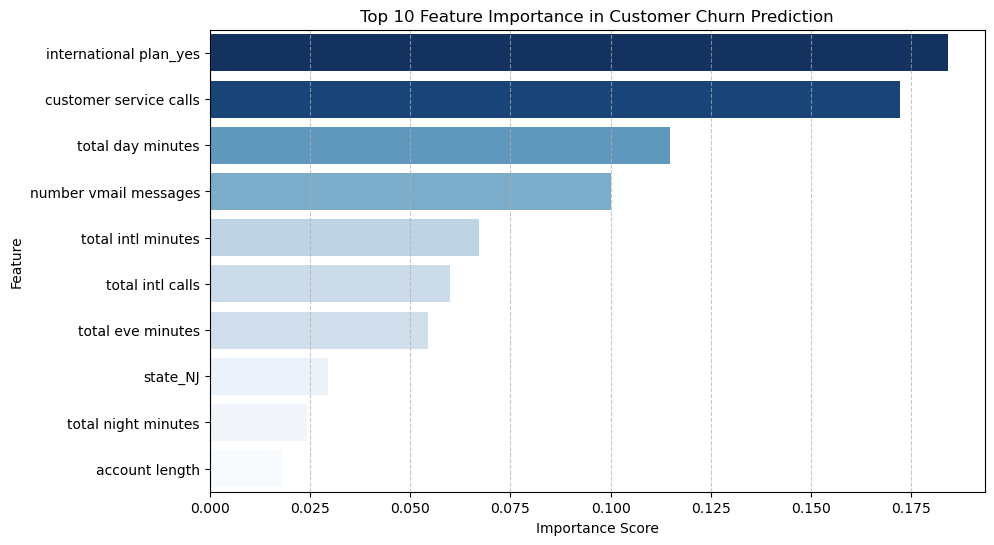

In [10]:
# Sort features by importance
feature_importance = pd.DataFrame({'Feature': X_train.columns, 'Importance': best_xgb.feature_importances_})
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)


# Select only the top 10 most important features
top_features = feature_importance.head(10)


# Set figure size
plt.figure(figsize=(10, 6))


# Create horizontal bar plot for better readability
sns.barplot(y=top_features['Feature'], x=top_features['Importance'], palette="Blues", hue=top_features['Importance'], legend=False)


# Adjust labels and title
plt.title('Top 10 Feature Importance in Customer Churn Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)  # Add grid for readability


plt.show()